In [1]:
import sys 
sys.path.append("..") # lets the notebook import from src/

import numpy as np
import pandas as pd

from src.data_preparation import load_data, split_data, save_splits, load_splits
from src.preprocessing import build_preprocessor

In [2]:
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print()
print("Train proportions:")
print(y_train.value_counts(normalize=True).round(3).to_string())
print()
print("Test proportions:")
print(y_test.value_counts(normalize=True).round(3).to_string())
save_splits(X_train, X_test, y_train, y_test)
print("Splits saved in data/processed/")

X_train: (1600, 15) | X_test: (400, 15)

Train proportions:
Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33

Test proportions:
Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Splits saved in data/processed/


In [3]:
preprocessor = build_preprocessor()

X_train_prep = preprocessor.fit_transform(X_train) # learn + apply
X_test_prep = preprocessor.transform(X_test)       # apply only

print("X_train_prep:", X_train_prep.shape)
print("X_test_prep:", X_test_prep.shape)
print("NaN left in train:", np.isnan(X_train_prep).sum())
print("NaN left in test:", np.isnan(X_test_prep).sum())

X_train_prep: (1600, 14)
X_test_prep: (400, 14)
NaN left in train: 0
NaN left in test: 0


In [4]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from src.train import get_models, tune_logistic_regression, tune_gradient_boosting
from src.evaluate import compare_models, cv_confusion_matrix, LABELS

In [5]:
X_train, X_test, y_train, y_test = load_splits()

models = get_models()
results = compare_models(models, X_train, y_train)
print(results.to_string())

                     accuracy  precision  recall     f1  roc_auc  train_accuracy
model                                                                           
Logistic Regression     0.752      0.753   0.751  0.751    0.905           0.768
Random Forest           0.669      0.662   0.668  0.663    0.850           1.000
Gradient Boosting       0.694      0.693   0.694  0.693    0.859           0.920


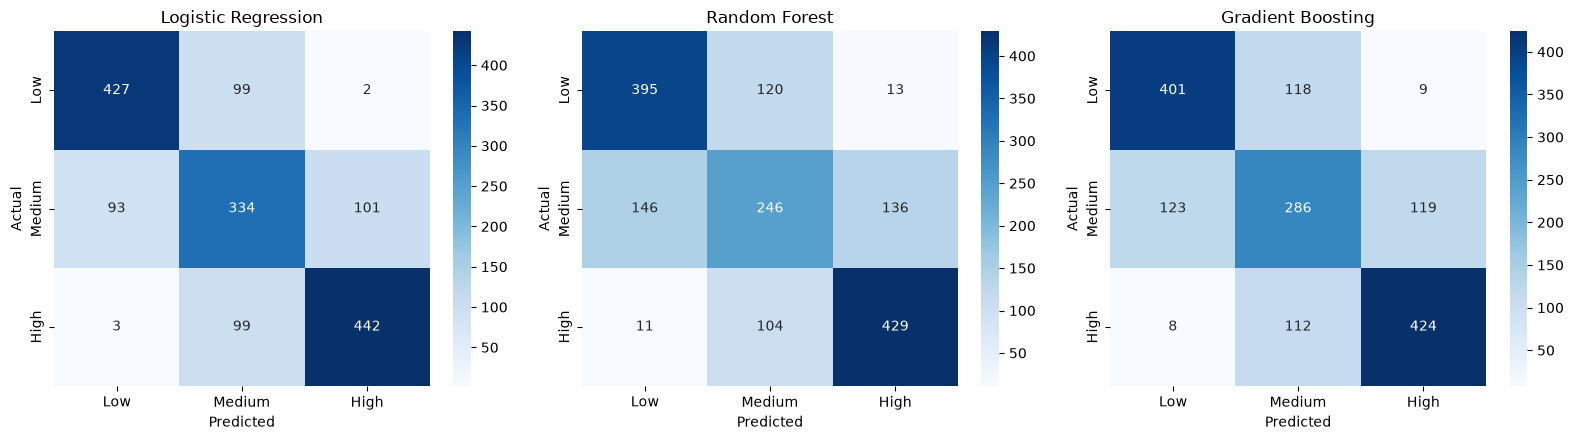

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, pipe) in zip(axes, models.items()):
    cm = cv_confusion_matrix(pipe, X_train, y_train)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [7]:
lr_search = tune_logistic_regression(X_train, y_train)

print("Best parameters:", lr_search.best_params_)
print("Best CV f1:", round(lr_search.best_score_, 3))

Best parameters: {'model__C': 10}
Best CV f1: 0.752


In [8]:
gb_search = tune_gradient_boosting(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print("Best CV f1:", round(gb_search.best_score_, 3))

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 100, 'model__min_samples_leaf': 30, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Best CV f1: 0.709


In [9]:
tuned_models = {
    "LR (tuned)": lr_search.best_estimator_,
    "Gradient Boosting (tuned)": gb_search.best_estimator_,
}
tuned_results = compare_models(tuned_models, X_train, y_train)

all_results = pd.concat([results, tuned_results])
print(all_results.sort_values("f1", ascending=False).to_string())

                           accuracy  precision  recall     f1  roc_auc  train_accuracy
model                                                                                 
LR (tuned)                    0.752      0.754   0.751  0.752    0.905           0.768
Logistic Regression           0.752      0.753   0.751  0.751    0.905           0.768
Gradient Boosting (tuned)     0.709      0.711   0.709  0.709    0.870           0.888
Gradient Boosting             0.694      0.693   0.694  0.693    0.859           0.920
Random Forest                 0.669      0.662   0.668  0.663    0.850           1.000


In [10]:
from sklearn.metrics import confusion_matrix, classification_report
from src.train import train_final_model, save_model
from src.evaluate import evaluate_on_test, LABELS

In [11]:
# train the final model 
final_model = train_final_model(X_train, y_train)

test_metrics, y_pred = evaluate_on_test(final_model, X_test, y_test)
for name, value in test_metrics.items():
    print(f"{name:16s} {value}")

print()
print(classification_report(y_test, y_pred, labels=LABELS))

accuracy         0.755
precision_macro  0.754
recall_macro     0.754
f1_macro         0.754
f1_weighted      0.755
roc_auc          0.913

              precision    recall  f1-score   support

         Low       0.81      0.80      0.80       132
      Medium       0.63      0.63      0.63       132
        High       0.81      0.84      0.83       136

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.76      0.75       400



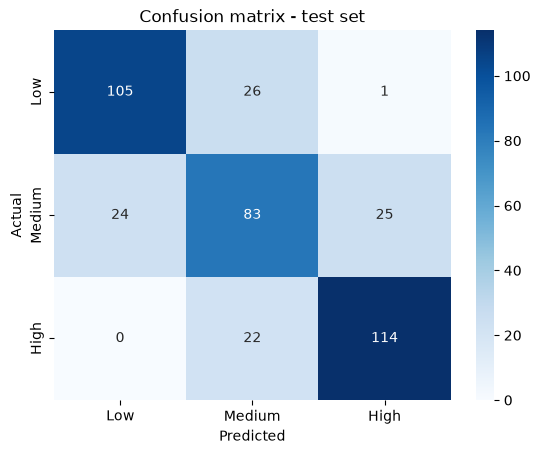

Low <-> High confusions (the serious errors): 1 out of 400


In [12]:
# test confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=LABELS)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion matrix - test set")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Low <-> High confusions (the serious errors):",
      cm[0, 2] + cm[2, 0], "out of", len(y_test))

In [13]:
# error analysis
errors = X_test.copy()
errors["actual"] = y_test.values
errors["predicted"] = y_pred
errors["correct"] = errors["actual"] == errors["predicted"]

print("Accuracy by gender:")
print(errors.groupby("Gender")["correct"].agg(["mean", "count"]).round(3).to_string())
print()

print("Average values: correct vs wrong predictions")
cols = ["Sleep_Hours", "GPA", "Financial_Stress", "Family_Support"]
print(errors.groupby("correct")[cols].mean().round(2).to_string())

Accuracy by gender:
             mean  count
Gender                  
Female      0.802    192
Male        0.710    186
Non-binary  0.727     22

Average values: correct vs wrong predictions
         Sleep_Hours   GPA  Financial_Stress  Family_Support
correct                                                     
False           6.78  2.55              5.80            6.38
True            6.79  2.56              5.97            6.53


Previous_Mental_Health_History    2.553
Sleep_Hours                      -2.300
Financial_Stress                  1.451
Family_Support                   -1.169
Part_Time_Job                     1.054
Physical_Activity                -0.925
GPA                              -0.819
Diet_Quality                     -0.622
Social_Media_Hours                0.571
Screen_Time_Hours                 0.217
Attendance_Rate                  -0.185
Year_of_Study                    -0.070
Age                               0.013
Study_Hours_Per_Week              0.003


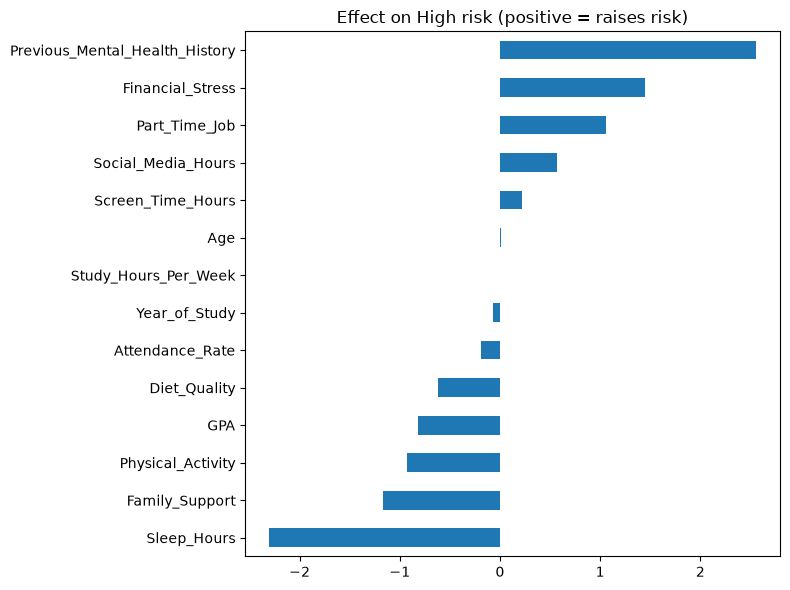

In [14]:
# feature importance
from src.preprocessing import NUMERIC_COLS, ORDINAL_COLS, BINARY_COLS

feature_names = NUMERIC_COLS + ORDINAL_COLS + BINARY_COLS  # same order as the preprocessor
lr = final_model.named_steps["model"]
high_idx = list(lr.classes_).index("High")

importance = pd.Series(lr.coef_[high_idx], index=feature_names).sort_values(key=abs, ascending=False)
print(importance.round(3).to_string())

importance.sort_values().plot(kind="barh", figsize=(8, 6),
                              title="Effect on High risk (positive = raises risk)")
plt.tight_layout()
plt.show()

In [15]:
path = save_model(final_model)
print("Saved:", path)

Saved: C:\Users\ycode\Desktop\student-wellbeing-ml\models\student_risk_pipeline.joblib
